# M2. 행렬 곱은 왜 "행 × 열"인가

**목표**
- 행렬을 "공간을 옮기는 규칙"으로 봅니다. 행렬의 **열**은 기본 축 e1, e2 가 옮겨 가는 자리입니다.
- 변환 두 개를 이어 붙인 결과를 하나의 행렬로 쓰려고 하면, **행 × 열 규칙이 저절로 나온다**는 것을 유도합니다.
- 같은 곱을 네 가지 눈(내적의 표, 열의 가중합, 행의 가중합, rank-1 조각의 합)으로 봅니다.
- 모양 규칙, 순서를 바꾸면 안 되는 이유, 단위행렬·역행렬·행렬식, 전치를 봅니다.
- 표본 × 유전자 표, 신경망 한 층, 계산 비용(n³)으로 응용을 봅니다.

**이 노트북이 답하는 질문**: 행렬 곱은 왜 하필 "앞 행렬의 행과 뒤 행렬의 열을 내적"하는 이상한 규칙인가?

**같이 볼 강의**
- MIT 18.06 (Strang, 2010 봄) Lecture 3 "Multiplication and inverse matrices", Lecture 18 "Properties of determinants", Lecture 30 "Linear transformations and their matrices" [1]
- 3Blue1Brown "Essence of linear algebra" Chapter 3 "Linear transformations and matrices", Chapter 4 "Matrix multiplication as composition", Chapter 6 "The determinant", Chapter 7 "Inverse matrices, column space and null space", Chapter 8 "Nonsquare matrices as transformations between dimensions" [2]

문장 끝의 `[번호]` 는 맨 아래 **출처** 절의 번호입니다. 그림 속 숫자는 따로 밝히지 않으면 **이 노트북의 장난감 예**입니다. 내적은 [M1](lab01_vectors-dot.ipynb)을 보세요.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 색의 뜻은 행렬 노트북 M1~M5 공통
# e1·첫째 열 = 파랑, e2·둘째 열 = 빨강, 결과 = 초록, 변환 전 격자 = 옅은 회색, 변환 뒤 격자 = 진회색, 핵심 메시지 = 자주
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Polygon, Rectangle

COL = dict(e1="#0072B2", e2="#D55E00", result="#009E73", grid0="#D1D5DB", grid1="#374151",
           extra="#E69F00", sky="#56B4E9", highlight="#CC79A7", ink="#222222", muted="#6B7280",
           grid="#E5E7EB", shade="#FFF4E0", neutral="#F3F4F6")


def apply_theme():
    import logging
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}")


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """핵심 메시지: 자주색 굵은 글씨(흰 바탕)"""
    kw.setdefault("fontsize", 10); kw.setdefault("ha", "left"); kw.setdefault("va", "center")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, color=COL["highlight"], fontweight="semibold", **kw)


def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.014):
    """수식을 조각(chip)으로 그린다. parts = [(mathtext, color 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 그림의 같은 색과 짝을 이룬다.
    조각마다 '조각과 이름표 중 넓은 쪽' 만큼 자리를 잡아 이름표끼리 겹치지 않게 한다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lab, lw = None, 0.0
        if label:
            lab = ax.text(0, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                          color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)
            lw = lab.get_window_extent(renderer=r).transformed(inv).width
        items.append((t, bb, color, lab, max(bb.width, lw)))
    total = sum(w for *_, w in items) + gap * (len(items) - 1)
    x = (1 - total) / 2                                    # 가운데 정렬
    for t, bb, color, lab, w in items:
        x0 = x + (w - bb.width) / 2                         # 자리 가운데에 조각
        t.set_x(x0)
        if color:
            ax.add_patch(FancyBboxPatch((x0 - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if lab is not None:
            lab.set_x(x0 + bb.width / 2)
        x += w + gap


def show_formula(parts, title=None, height=1.35, width=10.5, fontsize=17):
    """수식 조각 그림 한 장(제목은 가운데)"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts, fontsize=fontsize)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11, fontweight="semibold",
                color=COL["ink"], transform=ax.transAxes)
    plt.show()


def arrow(ax, start, end, color, lw=2.2, label=None, label_off=(0.08, 0.08), zorder=4, ls="-", **kw):
    """두 점 사이 화살표(데이터 좌표) + 끝에 이름표"""
    a = FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, lw=lw, color=color,
                        zorder=zorder, linestyle=ls, shrinkA=0, shrinkB=0)
    ax.add_patch(a)
    if label:
        ax.text(end[0] + label_off[0], end[1] + label_off[1], label, color=color, fontsize=10.5,
                fontweight="semibold", zorder=zorder + 1, **kw)
    return a


def concept_map(boxes, edges, title="Concept map", size=(11, 3.6)):
    """개념 지도: boxes = {key: (x, y, text, color)}, edges = [(from, to), ...] (축 좌표 0~1)"""
    fig, ax = plt.subplots(figsize=size); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    for k, (x, y, text, color) in boxes.items():
        ax.text(x, y, text, ha="center", va="center", fontsize=9.5, color=COL["ink"], zorder=3,
                bbox=dict(boxstyle="round,pad=0.45", facecolor=color, edgecolor="none", alpha=0.9))
    for a, b in edges:
        (x0, y0, *_), (x1, y1, *_) = boxes[a], boxes[b]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.1,
                                    shrinkA=26, shrinkB=26, connectionstyle="arc3,rad=0.0"))
    ax.set_title(title)
    plt.show()


apply_theme()


def draw_concept_map_m2():
    boxes = {
        "T": (0.08, 0.55, "matrix =\nrule that moves space", COL["neutral"]),
        "cols": (0.27, 0.85, "columns = where\ne1, e2 land", "#DCEBF7"),
        "Ax": (0.27, 0.25, "A x = weighted sum\nof columns", "#DCEBF7"),
        "comp": (0.48, 0.55, "do B, then A\n= one matrix AB", COL["neutral"]),
        "rule": (0.66, 0.85, "row · column rule\n(derived)", "#D9F2E6"),
        "views": (0.66, 0.25, "four views of AB", "#D9F2E6"),
        "order": (0.86, 0.85, "order matters\nAB ≠ BA", COL["neutral"]),
        "inv": (0.86, 0.55, "identity, inverse,\ndeterminant", COL["neutral"]),
        "app": (0.86, 0.22, "samples × genes,\nNN layer, cost n³", "#FDE7D2"),
    }
    edges = [("T", "cols"), ("T", "Ax"), ("cols", "comp"), ("Ax", "comp"), ("comp", "rule"),
             ("comp", "views"), ("rule", "order"), ("comp", "inv"), ("views", "app")]
    concept_map(boxes, edges, title="M2 concept map: the product rule comes from doing one transformation after another")


def _grid(ax, M, color, lw, extent=3, step=1, alpha=1.0, zorder=1):
    """정수 격자선을 행렬 M 으로 옮겨 그린다"""
    M = np.asarray(M, float)
    t = np.linspace(-extent, extent, 2)
    for c in np.arange(-extent, extent + step, step):
        for line in (np.array([[c, c], t]), np.array([t, [c, c]])):
            p = M @ line
            ax.plot(p[0], p[1], color=color, lw=lw, alpha=alpha, zorder=zorder, solid_capstyle="butt")


def _frame(ax, lim=3.2):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def _matrix_label(ax, M, x, y, name, fontsize=12, col_colors=(None, None)):
    """2×2 행렬을 열 색으로 적는다(축 좌표, (x, y) = 왼쪽 가운데), 흰 바탕 상자 위에"""
    M = np.asarray(M)
    ax.add_patch(FancyBboxPatch((x - 0.01, y - 0.09), 0.32, 0.18, boxstyle="round,pad=0,rounding_size=0.02",
                                transform=ax.transAxes, facecolor="white", edgecolor=COL["grid0"], lw=0.8, zorder=5))
    ax.text(x + 0.02, y, f"{name} =", ha="left", va="center", fontsize=fontsize, transform=ax.transAxes,
            color=COL["ink"], zorder=6)
    for j in range(2):
        c = col_colors[j] or COL["ink"]
        for i in range(2):
            ax.text(x + 0.17 + j * 0.08, y + 0.04 - i * 0.08, f"{M[i, j]:g}", ha="center", va="center",
                    fontsize=fontsize, color=c, fontweight="semibold", transform=ax.transAxes, zorder=6)


def draw_transform(A=((2, -1), (1, 1))):
    A = np.array(A, float)
    fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))
    L, R = ax
    _grid(L, np.eye(2), COL["grid0"], 1.0)
    arrow(L, (0, 0), (1, 0), COL["e1"], lw=3, label="e1 = (1, 0)", label_off=(0.05, -0.35))
    arrow(L, (0, 0), (0, 1), COL["e2"], lw=3, label="e2 = (0, 1)", label_off=(-0.9, 0.12))
    _frame(L); panel(L, "A", "Before: the ordinary grid")
    _grid(R, np.eye(2), COL["grid0"], 0.8, alpha=0.6, zorder=0)
    _grid(R, A, COL["grid1"], 0.9, zorder=1, extent=5, alpha=0.8)
    arrow(R, (0, 0), A[:, 0], COL["e1"], lw=3)
    arrow(R, (0, 0), A[:, 1], COL["e2"], lw=3)
    box = dict(facecolor="white", edgecolor="none", pad=1.2)
    R.text(A[0, 0] + 0.1, A[1, 0] - 0.45, f"A e1 = ({A[0, 0]:g}, {A[1, 0]:g})", color=COL["e1"], fontsize=10.5,
           fontweight="semibold", bbox=box, zorder=6)
    R.text(A[0, 1] - 1.9, A[1, 1] + 0.2, f"A e2 = ({A[0, 1]:g}, {A[1, 1]:g})", color=COL["e2"], fontsize=10.5,
           fontweight="semibold", bbox=box, zorder=6)
    _frame(R); panel(R, "B", "After A: every grid line moves")
    _matrix_label(R, A, 0.66, 0.1, "A", col_colors=(COL["e1"], COL["e2"]))
    callout(R, -3.1, 2.95, "column 1 of A = where e1 lands\ncolumn 2 of A = where e2 lands", fontsize=10, va="top", zorder=7)
    plt.tight_layout(); plt.show()


def draw_Ax_columns(A=((2, -1), (1, 1)), x=(2, 1)):
    A = np.array(A, float); x = np.array(x, float); c1, c2 = A[:, 0], A[:, 1]
    fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))
    L, R = ax
    _grid(L, np.eye(2), COL["grid0"], 1.0, extent=5)
    arrow(L, (0, 0), (x[0], 0), COL["e1"], lw=3, label=f"{x[0]:g} × e1", label_off=(-0.6, -0.45))
    arrow(L, (x[0], 0), (x[0], x[1]), COL["e2"], lw=3, label=f"{x[1]:g} × e2", label_off=(0.1, -0.5))
    arrow(L, (0, 0), x, COL["result"], lw=2.2, ls="--", label=f"x = ({x[0]:g}, {x[1]:g})", label_off=(-0.4, 0.2))
    _frame(L, 4.6); panel(L, "A", "x = 2 steps of e1 + 1 step of e2")
    _grid(R, np.eye(2), COL["grid0"], 0.8, alpha=0.6, zorder=0, extent=5)
    _grid(R, A, COL["grid1"], 0.9, zorder=1, extent=6, alpha=0.8)
    arrow(R, (0, 0), c1, COL["e1"], lw=3)
    arrow(R, c1, 2 * c1, COL["e1"], lw=3, label=f"{x[0]:g} × column 1", label_off=(-0.25, -0.6))
    arrow(R, 2 * c1, 2 * c1 + c2, COL["e2"], lw=3, label=f"{x[1]:g} × column 2", label_off=(0.35, -0.35))
    y = A @ x
    arrow(R, (0, 0), y, COL["result"], lw=2.4, ls="--", label=f"A x = ({y[0]:g}, {y[1]:g})", label_off=(-1.85, 0.25))
    _frame(R, 4.6); panel(R, "B", "A x = the same steps, taken along A's columns")
    callout(R, -4.4, -4.1, "same recipe (2, 1), new ingredients (the columns)", fontsize=10, zorder=7)
    plt.tight_layout(); plt.show()
    return y


def draw_composition(A=((0, -1), (1, 0)), B=((1, 1), (0, 1))):
    A = np.array(A, float); B = np.array(B, float); AB = A @ B
    fig, ax = plt.subplots(1, 3, figsize=(12, 4.6))
    stages = [(np.eye(2), "A", "Start"), (B, "B", "1st: apply B (shear)"), (AB, "C", "2nd: apply A (rotate 90°) → AB")]
    for k, (M, let, title) in enumerate(stages):
        a = ax[k]
        _grid(a, np.eye(2), COL["grid0"], 0.7, alpha=0.5, zorder=0)
        if k:
            _grid(a, M, COL["grid1"], 0.9, zorder=1, extent=5, alpha=0.8)
        arrow(a, (0, 0), M[:, 0], COL["e1"], lw=3)
        arrow(a, (0, 0), M[:, 1], COL["e2"], lw=3)
        a.text(M[0, 0] + 0.12, M[1, 0] - 0.35, f"({M[0, 0]:g}, {M[1, 0]:g})", color=COL["e1"], fontsize=10, fontweight="semibold")
        a.text(M[0, 1] + (0.12 if M[0, 1] >= 0 else -1.05), M[1, 1] + 0.15, f"({M[0, 1]:g}, {M[1, 1]:g})",
               color=COL["e2"], fontsize=10, fontweight="semibold")
        _frame(a, 2.6); panel(a, let, title)
    callout(ax[2], -2.5, -2.3, "AB's columns = A applied to B's columns", fontsize=9.8)
    plt.tight_layout(); plt.show()
    return AB


def _cells(ax, M, x0, y0, w=0.62, h=0.5, colors=None, fmt="{:g}", fs=12, alpha=0.18, edge=None):
    """행렬 칸을 둥근 상자로(데이터 좌표, 왼쪽 위가 (x0, y0))"""
    M = np.atleast_2d(M)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            c = colors[i][j] if colors is not None else COL["neutral"]
            x, y = x0 + j * w, y0 - i * h
            ax.add_patch(FancyBboxPatch((x + 0.03, y - h + 0.04), w - 0.06, h - 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.06", facecolor=c,
                                        alpha=alpha if c != COL["neutral"] else 1, edgecolor=edge or "none", lw=1.2))
            ax.text(x + w / 2, y - h / 2, fmt.format(M[i, j]), ha="center", va="center", fontsize=fs, color=COL["ink"])
    return x0 + M.shape[1] * w


def draw_row_col_origin(A=((1, 2), (3, 4)), B=((5, 6), (7, 8))):
    A = np.array(A); B = np.array(B); b1 = B[:, 0]
    fig, ax = plt.subplots(figsize=(11, 2.9)); ax.set_axis_off(); ax.set_xlim(0, 12.6); ax.set_ylim(-0.15, 1.75)
    cA = [[COL["e1"], COL["e2"]], [COL["e1"], COL["e2"]]]
    x = _cells(ax, A, 0.3, 1.6, colors=cA); ax.text(x + 0.15, 1.1, "×", fontsize=16, va="center")
    cb = [[COL["extra"]], [COL["extra"]]]
    x = _cells(ax, b1[:, None], x + 0.5, 1.6, colors=cb)
    ax.text(x + 0.2, 1.1, "=", fontsize=16, va="center")
    ax.text(x + 0.75, 1.1, f"{b1[0]} ×", fontsize=13, va="center", color=COL["extra"], fontweight="semibold")
    x2 = _cells(ax, A[:, [0]], x + 1.6, 1.6, colors=[[COL["e1"]], [COL["e1"]]])
    ax.text(x2 + 0.15, 1.1, "+", fontsize=16, va="center")
    ax.text(x2 + 0.6, 1.1, f"{b1[1]} ×", fontsize=13, va="center", color=COL["extra"], fontweight="semibold")
    x3 = _cells(ax, A[:, [1]], x2 + 1.45, 1.6, colors=[[COL["e2"]], [COL["e2"]]])
    ax.text(x3 + 0.2, 1.1, "=", fontsize=16, va="center")
    col = A @ b1
    _cells(ax, col[:, None], x3 + 0.6, 1.6, colors=[[COL["result"]], [COL["result"]]])
    ax.text(x3 + 1.5, 1.35, f"← {A[0, 0]}×{b1[0]} + {A[0, 1]}×{b1[1]} = {col[0]}", fontsize=10.5, va="center", color=COL["ink"])
    ax.text(x3 + 1.5, 0.85, f"← {A[1, 0]}×{b1[0]} + {A[1, 1]}×{b1[1]} = {col[1]}", fontsize=10.5, va="center", color=COL["ink"])
    callout(ax, 0.3, 0.05, "top entry = row 1 of A  ·  column 1 of B  →  that is where 'row × column' comes from", fontsize=10.5)
    plt.show()


def draw_four_views(A=((1, 2), (3, 4)), B=((5, 6), (7, 8))):
    A = np.array(A); B = np.array(B); C = A @ B
    fig, axs = plt.subplots(2, 2, figsize=(11, 5.4))
    for a in axs.ravel():
        a.set_axis_off(); a.set_xlim(0, 6.0); a.set_ylim(-0.35, 1.5)
    N = COL["neutral"]
    # 1. 내적의 표: (1, 2) 칸
    a = axs[0, 0]
    x = _cells(a, A, 0.1, 1.4, colors=[[COL["sky"]] * 2, [N, N]]); a.text(x + 0.1, 0.9, "×", fontsize=14, va="center")
    x = _cells(a, B, x + 0.4, 1.4, colors=[[N, COL["e2"]], [N, COL["e2"]]]); a.text(x + 0.1, 0.9, "=", fontsize=14, va="center")
    _cells(a, C, x + 0.4, 1.4, colors=[[N, COL["result"]], [N, N]])
    note(a, 0.1, -0.15, f"row 1 of A · column 2 of B = 1×6 + 2×8 = {C[0, 1]}", fontsize=9.5, color=COL["ink"])
    panel(a, "1", "Table of dot products (row · column)")
    # 2. 열: AB 의 2열 = A × (B 의 2열)
    a = axs[0, 1]
    x = _cells(a, A, 0.1, 1.4, colors=[[COL["e1"], COL["e2"]], [COL["e1"], COL["e2"]]]); a.text(x + 0.1, 0.9, "×", fontsize=14, va="center")
    x = _cells(a, B, x + 0.4, 1.4, colors=[[N, COL["extra"]], [N, COL["extra"]]]); a.text(x + 0.1, 0.9, "=", fontsize=14, va="center")
    _cells(a, C, x + 0.4, 1.4, colors=[[N, COL["result"]], [N, COL["result"]]])
    note(a, 0.1, -0.15, "column 2 of AB = 6 × (blue column) + 8 × (red column) of A", fontsize=9.5, color=COL["ink"])
    panel(a, "2", "Columns: mix A's columns")
    # 3. 행: AB 의 1행 = (A 의 1행) × B
    a = axs[1, 0]
    x = _cells(a, A, 0.1, 1.4, colors=[[COL["extra"]] * 2, [N, N]]); a.text(x + 0.1, 0.9, "×", fontsize=14, va="center")
    x = _cells(a, B, x + 0.4, 1.4, colors=[[COL["sky"]] * 2, [COL["grid1"]] * 2]); a.text(x + 0.1, 0.9, "=", fontsize=14, va="center")
    _cells(a, C, x + 0.4, 1.4, colors=[[COL["result"]] * 2, [N, N]])
    note(a, 0.1, -0.15, "row 1 of AB = 1 × (sky-blue row) + 2 × (grey row) of B", fontsize=9.5, color=COL["ink"])
    panel(a, "3", "Rows: mix B's rows")
    # 4. rank-1 조각의 합
    a = axs[1, 1]
    o1 = np.outer(A[:, 0], B[0]); o2 = np.outer(A[:, 1], B[1])
    x = _cells(a, o1, 0.1, 1.4, colors=[[COL["e1"]] * 2] * 2); a.text(x + 0.1, 0.9, "+", fontsize=14, va="center")
    x = _cells(a, o2, x + 0.4, 1.4, colors=[[COL["e2"]] * 2] * 2); a.text(x + 0.1, 0.9, "=", fontsize=14, va="center")
    _cells(a, C, x + 0.4, 1.4, colors=[[COL["result"]] * 2] * 2)
    note(a, 0.1, -0.15, "(col 1 of A)(row 1 of B)  +  (col 2 of A)(row 2 of B)", fontsize=9.5, color=COL["ink"])
    panel(a, "4", "Sum of rank-1 pieces (outer products)")
    plt.tight_layout(); plt.show()


def draw_shapes(m=5, n=3, p=1):
    fig, ax = plt.subplots(figsize=(11, 3.7)); ax.set_axis_off(); ax.set_xlim(0, 12.5); ax.set_ylim(-0.9, 6.0)
    s = 0.85; top = 5.2
    def box(x, rows, cols, color, label, dim_left, dim_top, hl_left=False, hl_top=False):
        ax.add_patch(FancyBboxPatch((x, top - rows * s), cols * s, rows * s, boxstyle="round,pad=0,rounding_size=0.08",
                                    facecolor=color, alpha=0.18, edgecolor=color, lw=1.5))
        ax.text(x + cols * s / 2, top - rows * s - 0.35, label, ha="center", va="top", fontsize=10, color=COL["ink"])
        ax.text(x - 0.12, top - rows * s / 2, dim_left, ha="right", va="center", fontsize=11, fontweight="semibold",
                color=COL["highlight"] if hl_left else COL["muted"])
        ax.text(x + cols * s / 2, top + 0.12, dim_top, ha="center", va="bottom", fontsize=11, fontweight="semibold",
                color=COL["highlight"] if hl_top else COL["muted"])
        return x + cols * s
    x = box(0.9, m, n, COL["e1"], "X: samples × genes", f"{m}", f"{n}", hl_top=True)
    ax.text(x + 0.35, 3.0, "×", fontsize=18, va="center")
    x = box(x + 1.0, n, p, COL["e2"], "w: gene weights", f"{n}", f"{p}", hl_left=True)
    ax.text(x + 0.35, 3.0, "=", fontsize=18, va="center")
    x = box(x + 1.0, m, p, COL["result"], "score: one per sample", f"{m}", f"{p}")
    callout(ax, x + 0.7, 4.6, f"purple sizes must match ({n} genes = {n} weights)\n"
                               f"grey sizes are what is left: {m} × {p}\n\n({m} × {n}) · ({n} × {p}) → {m} × {p}",
            fontsize=10.5, va="top")
    plt.show()


def _F_shape():
    return np.array([[0, 0], [0, 2], [1.2, 2], [1.2, 1.6], [0.4, 1.6], [0.4, 1.15], [1.0, 1.15],
                     [1.0, 0.75], [0.4, 0.75], [0.4, 0]]).T


def draw_order_matters(R=((0, -1), (1, 0)), S=((1, 1), (0, 1))):
    R = np.array(R, float); S = np.array(S, float); F = 0.85 * _F_shape()
    fig, ax = plt.subplots(1, 3, figsize=(12, 4.4))
    for a, M, let, title, c in [(ax[0], np.eye(2), "A", "Start", COL["muted"]),
                                (ax[1], R @ S, "B", "Shear first, then rotate: R S", COL["result"]),
                                (ax[2], S @ R, "C", "Rotate first, then shear: S R", COL["result"])]:
        _grid(a, np.eye(2), COL["grid0"], 0.6, alpha=0.5, zorder=0)
        P = M @ F
        a.add_patch(Polygon(P.T, closed=True, facecolor=c, alpha=0.25, edgecolor=c, lw=1.8, zorder=2))
        _frame(a, 3.4); panel(a, let, title)
    callout(ax[2], -3.3, -3.0, "same two moves, different order → different result", fontsize=9.8)
    plt.tight_layout(); plt.show()


def draw_determinant():
    mats = [("A   det = 2: area doubles", np.array([[2.0, 0.5], [0.0, 1.0]])),
            ("B   det = −1: area kept, flipped", np.array([[0.0, 1.0], [1.0, 0.0]])),
            ("C   det = 0: squashed onto a line", np.array([[1.0, 2.0], [0.5, 1.0]]))]
    fig, ax = plt.subplots(1, 3, figsize=(12, 4.4))
    sq = np.array([[0, 0], [1, 0], [1, 1], [0, 1]]).T
    F = 0.45 * _F_shape() + np.array([[0.3], [0.05]])          # 정사각형 안의 비대칭 F: 뒤집힘이 보이게
    for a, (title, M) in zip(ax, mats):
        _grid(a, np.eye(2), COL["grid0"], 0.6, alpha=0.5, zorder=0)
        a.add_patch(Polygon(sq.T, closed=True, facecolor=COL["grid0"], alpha=0.45, edgecolor=COL["muted"], lw=1, zorder=1))
        a.add_patch(Polygon(F.T, closed=True, facecolor="none", edgecolor=COL["muted"], lw=1, zorder=1))
        P = M @ sq; PF = M @ F
        a.add_patch(Polygon(P.T, closed=True, facecolor=COL["result"], alpha=0.18, edgecolor=COL["result"], lw=1.8, zorder=2))
        a.add_patch(Polygon(PF.T, closed=True, facecolor=COL["result"], alpha=0.55, edgecolor=COL["result"], lw=1.2, zorder=3))
        arrow(a, (0, 0), M[:, 0], COL["e1"], lw=2.4, zorder=4); arrow(a, (0, 0), M[:, 1], COL["e2"], lw=2.4, zorder=4)
        _frame(a, 3.4); a.set_title(title)
        a.text(-3.3, -3.2, f"ad − bc = {M[0, 0]:g}×{M[1, 1]:g} − {M[0, 1]:g}×{M[1, 0]:g} = {round(np.linalg.det(M), 6) + 0:g}",
               fontsize=9.5, color=COL["ink"])
    callout(ax[1], -3.3, 2.8, "the F is mirrored", fontsize=9.6)
    callout(ax[2], -3.3, 2.8, "no area left → cannot undo (no inverse)", fontsize=9.6)
    plt.tight_layout(); plt.show()


def draw_transpose(M=((1, 2, 3), (4, 5, 6))):
    M = np.array(M)
    fig, ax = plt.subplots(figsize=(9, 2.9)); ax.set_axis_off(); ax.set_xlim(0, 9.4); ax.set_ylim(-0.3, 2.0)
    rc = [[COL["sky"]] * 3, [COL["grid1"]] * 3]
    x = _cells(ax, M, 0.4, 1.4, colors=rc)
    ax.text(0.4 + 1.5 * 0.62, 0.15, "M: 2 × 3 (rows: sky blue, grey)", ha="center", fontsize=9.5, color=COL["muted"])
    ax.annotate("", xy=(x + 1.4, 0.9), xytext=(x + 0.3, 0.9), arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.4))
    ax.text(x + 0.85, 1.1, "flip over\nthe diagonal", ha="center", fontsize=9, color=COL["muted"])
    tc = [[COL["sky"], COL["grid1"]]] * 3
    _cells(ax, M.T, x + 1.8, 1.65, colors=tc, h=0.5)
    ax.text(x + 1.8 + 0.62, -0.18, "Mᵀ: 3 × 2 (rows became columns)", ha="center", fontsize=9.5, color=COL["muted"])
    plt.show()


def draw_samples_genes(seed=2):
    rng = np.random.default_rng(seed)
    X = np.round(rng.gamma(2.0, 2.0, (6, 4)), 1); w = np.array([0.5, 0.0, 1.0, -0.5])
    s = X @ w
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.2, 0.55, 0.8]})
    a = ax[0]
    a.imshow(X, cmap="Greys", vmin=0, vmax=X.max() * 2.2, aspect="auto")      # 옅게: 숫자가 읽히도록
    for i in range(6):
        for j in range(4):
            a.text(j, i, f"{X[i, j]:.1f}", ha="center", va="center", fontsize=9.5, color=COL["ink"])
    a.set_xticks(range(4), [f"gene {j + 1}" for j in range(4)]); a.set_yticks(range(6), [f"sample {i + 1}" for i in range(6)])
    for s_ in a.spines.values():
        s_.set_visible(False)
    a.tick_params(length=0)
    panel(a, "A", "X: 6 samples × 4 genes")
    a = ax[1]
    a.barh(range(4), w, color=COL["extra"], height=0.55)           # 가중치 = 조리법(주황)
    a.set_yticks(range(4), [f"gene {j + 1}" for j in range(4)]); a.invert_yaxis(); a.axvline(0, color=COL["muted"], lw=0.8)
    for j, v in enumerate(w):
        a.text(v + (0.06 if v >= 0 else -0.06), j, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=9.5)
    a.set_xlim(-1.0, 1.5); a.set_xlabel("weight")
    panel(a, "B", "w: gene weights")
    a = ax[2]
    a.barh(range(6), s, color=COL["result"], height=0.55)
    a.set_yticks(range(6), [f"sample {i + 1}" for i in range(6)]); a.invert_yaxis(); a.axvline(0, color=COL["muted"], lw=0.8)
    for i, v in enumerate(s):
        a.text(max(v, 0) + 0.2, i, f"{v:.2f}", va="center", ha="left", fontsize=9.5)
    a.set_xlim(min(0, s.min()) - 2.2, s.max() * 1.3); a.set_xlabel("score")
    panel(a, "C", "X w: one score per sample")
    plt.tight_layout(); plt.show()
    return X, w, s


def draw_nn_layer():
    fig, ax = plt.subplots(figsize=(10.5, 3.8)); ax.set_axis_off(); ax.set_xlim(0, 10); ax.set_ylim(0, 4)
    xin = [(1.5, 3.2), (1.5, 2.0), (1.5, 0.8)]; yout = [(4.5, 2.6), (4.5, 1.4)]
    W = np.array([[0.4, -1.0, 0.7], [1.2, 0.3, -0.5]])
    for j, (x0, y0) in enumerate(xin):
        for i, (x1, y1) in enumerate(yout):
            ax.plot([x0, x1], [y0, y1], color=COL["extra"], lw=0.8 + 1.8 * abs(W[i, j]), zorder=1,
                    ls="-" if W[i, j] >= 0 else (0, (3, 2)))
    for k, (x0, y0) in enumerate(xin):
        ax.add_patch(plt.Circle((x0, y0), 0.28, facecolor="white", edgecolor=COL["grid1"], lw=1.4, zorder=2))
        ax.text(x0, y0, f"x{k + 1}", ha="center", va="center", fontsize=10, zorder=3)
    for k, (x0, y0) in enumerate(yout):
        ax.add_patch(plt.Circle((x0, y0), 0.28, facecolor="#D9F2E6", edgecolor=COL["result"], lw=1.4, zorder=2))
        ax.text(x0, y0, f"y{k + 1}", ha="center", va="center", fontsize=10, zorder=3)
    ax.text(1.5, 0.15, "inputs (3)", ha="center", fontsize=9.5, color=COL["muted"])
    ax.text(4.5, 0.75, "outputs (2)", ha="center", fontsize=9.5, color=COL["muted"])
    ax.text(5.6, 3.3, "y = W x + b", fontsize=14, color=COL["ink"], fontweight="semibold")
    ax.text(5.6, 2.6, "W is 2 × 3: one row per output,\none column per input", fontsize=10, color=COL["muted"], va="top")
    ax.text(5.6, 1.6, "orange line = one weight (one cell of W)\nthicker = larger |weight|; dashed = negative", fontsize=9.5, color=COL["muted"], va="top")
    callout(ax, 5.6, 0.45, "a batch of N inputs at once:  Y = X Wᵀ + b  (N × 2)", fontsize=10)
    plt.show()
    return W


def draw_cost(ns=(64, 128, 256, 512, 1024, 1536), reps=3):
    import time
    rng = np.random.default_rng(0); times = []
    for n in ns:
        A_ = rng.random((n, n)); B_ = rng.random((n, n)); A_ @ B_
        best = min((lambda: (lambda t0: (A_ @ B_, time.perf_counter() - t0)[1])(time.perf_counter()))() for _ in range(reps))
        times.append(best)
    ns = np.array(ns, float); times = np.array(times)
    big = ns >= 512                                             # 큰 n 만 맞춤(작은 n 은 스레드·캐시 때문에 들쭉날쭉)
    slope = np.polyfit(np.log(ns[big]), np.log(times[big]), 1)[0]
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
    a = ax[0]
    a.plot(ns, ns ** 3, color=COL["ink"], lw=2, marker="o")
    for n in (256, 1024):
        e = int(np.log10(n ** 3))
        a.text(n * 1.08, n ** 3 * 0.75, f"{n}³ ≈ {n ** 3 / 10 ** e:.1f} × 10^{e}", va="top", fontsize=9)
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("matrix size n"); a.set_ylabel("multiplications")
    a.yaxis.grid(True); a.set_axisbelow(True)
    panel(a, "A", "Count: n² cells × n multiplications each")
    a = ax[1]
    a.plot(ns, times * 1e3, color=COL["result"], lw=2, marker="o")
    ref = times[-1] * 1e3 * (ns / ns[-1]) ** 3
    a.plot(ns, ref, color=COL["muted"], ls="--", lw=1.2)
    a.text(ns[1], ref[1], "slope 3 (n³)", fontsize=9, color=COL["muted"], va="bottom")
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("matrix size n"); a.set_ylabel("time on this PC (ms)")
    a.yaxis.grid(True); a.set_axisbelow(True)
    callout(a, ns[0], times[-1] * 1e3 * 0.6, f"measured slope ≈ {slope:.1f}", fontsize=10)
    panel(a, "B", "numpy A @ B, best of 3 runs")
    plt.tight_layout(); plt.show()
    return ns, times, slope

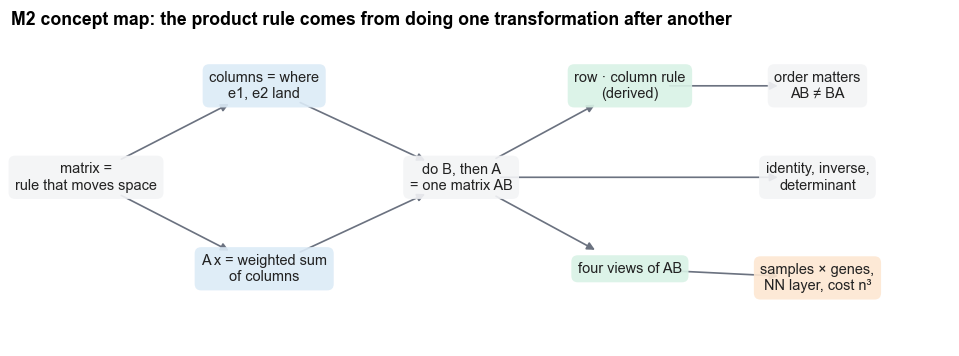

In [2]:
draw_concept_map_m2()

**그림에서 볼 것**
- 출발점은 "행렬은 공간을 옮기는 규칙"이라는 관점입니다. 여기서 열의 뜻(e1, e2 가 가는 곳)과 Ax 의 뜻(열의 가중합)이 나옵니다.
- 가운데 "B 를 하고 나서 A" 를 한 행렬로 쓰려는 순간 행 × 열 규칙과 네 가지 눈이 나옵니다. 오른쪽은 그 결과로 따라오는 성질과 응용입니다.

## 1. 행렬은 공간을 옮기는 규칙이다

**한 줄 정의**: 2 × 2 행렬은 평면의 모든 점을 다른 자리로 옮기는 규칙이고, 그 규칙은 **기본 축 e1 = (1, 0), e2 = (0, 1) 이 어디로 가는지**만 알면 다 정해집니다. 그 두 자리가 행렬의 두 열입니다(이 노트북의 2절에서 이유를 봅니다).

**왜 필요한가**: 행렬을 숫자 표로만 보면 곱셈 규칙이 외워야 할 약속처럼 보입니다. 변환으로 보면 규칙의 이유가 보입니다.

**숫자로 따라가기**: A = [[2, −1], [1, 1]] 이면 첫째 열 (2, 1) 이 e1 이 가는 곳, 둘째 열 (−1, 1) 이 e2 가 가는 곳입니다.

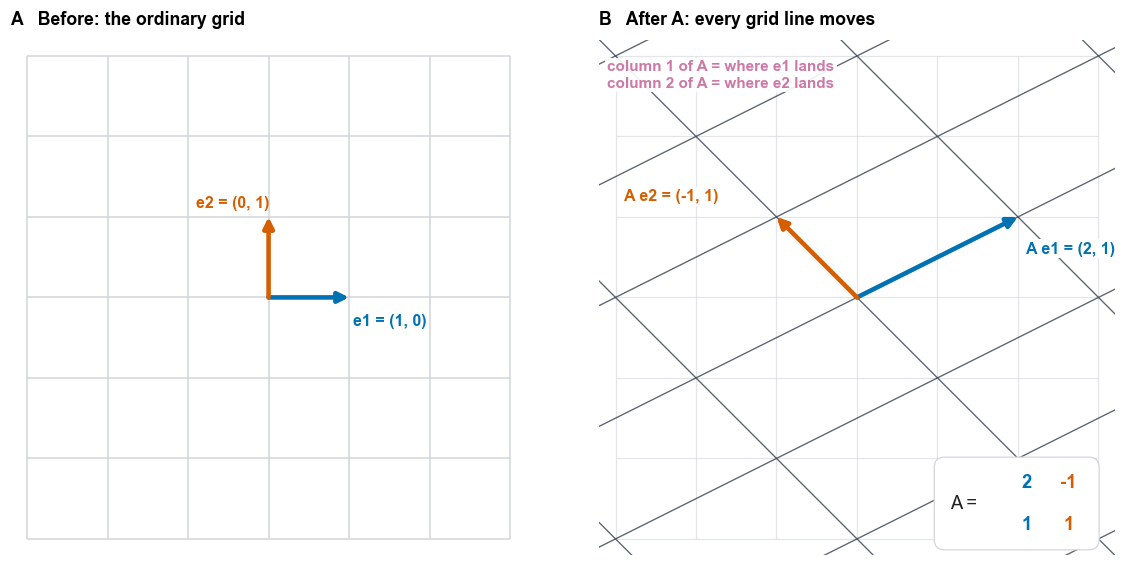

In [3]:
draw_transform()

**그림에서 볼 것**
- A: 옅은 회색 격자가 보통 좌표, 파란 화살표가 e1, 빨간 화살표가 e2 입니다.
- B: A 를 적용하면 격자 전체가 진회색으로 기울고 늘어납니다. 파란 e1 은 A 의 첫째 열 (2, 1) 로, 빨간 e2 는 둘째 열 (−1, 1) 로 갑니다.
- 격자선은 휘지 않고 곧은 채로, 서로 평행하고 같은 간격을 유지하며, **원점은 제자리**에 있습니다. 이것이 "선형" 변환의 성질입니다(원점까지 옮기는 평행이동은 선형이 아니라 행렬 곱 하나로 쓸 수 없습니다).

## 2. A x = 열의 가중합

**한 줄 정의**: 행렬 × 벡터는 "x 의 숫자만큼 A 의 열을 늘여 더하기"입니다. $Ax = x_1\,(\text{1열}) + x_2\,(\text{2열})$.

**왜 필요한가**: 1절에서 e1, e2 가 가는 곳만 알면 된다고 했습니다. 어떤 점 x 든 "e1 을 x₁ 번, e2 를 x₂ 번" 간 것이므로, 옮긴 뒤에는 "1열을 x₁ 번, 2열을 x₂ 번" 간 자리가 됩니다.

**숫자로 따라가기**: x = (2, 1) 이면 Ax = 2 × (2, 1) + 1 × (−1, 1) = (4, 2) + (−1, 1) = (3, 3) 입니다.

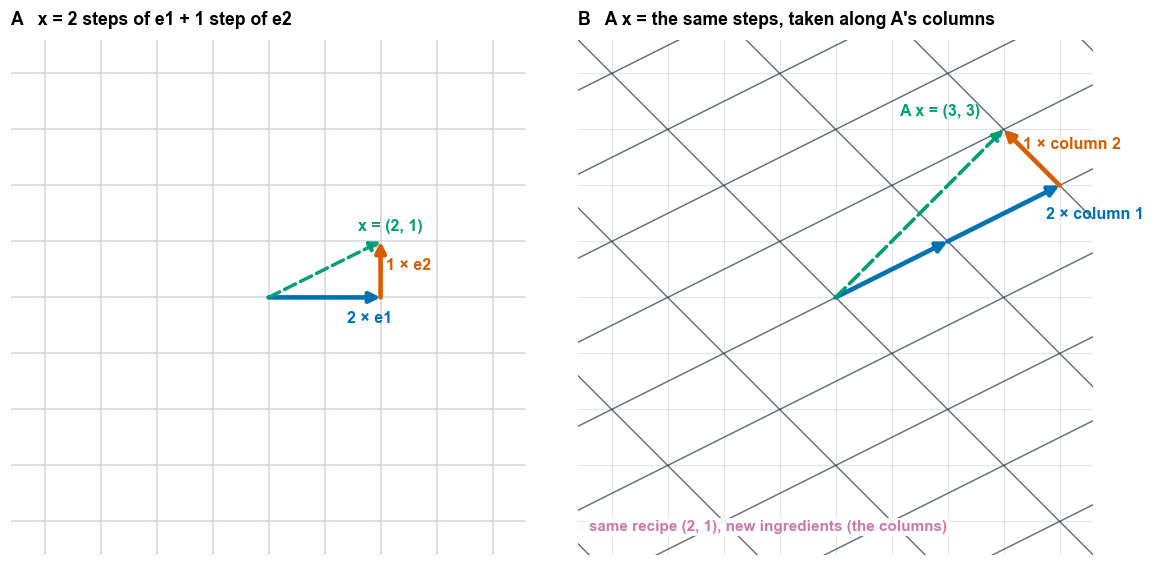

In [4]:
y = draw_Ax_columns()

**그림에서 볼 것**
- A: 보통 격자에서 x 는 파랑(e1) 두 칸, 빨강(e2) 한 칸입니다.
- B: 옮긴 격자에서도 **같은 걸음 수**(파랑 두 번, 빨강 한 번)를 가는데, 이번엔 걸음이 A 의 열입니다. 도착점 초록 (3, 3) 이 Ax 입니다.

**수식 풀어 읽기**

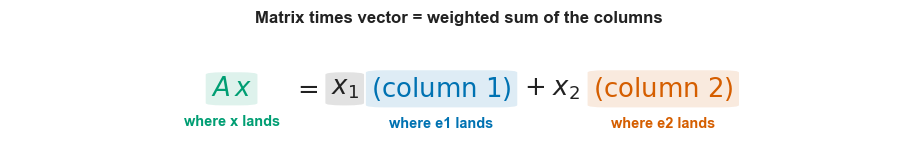

In [5]:
show_formula([(r"$A\,x$", COL["result"], "where x lands"), (r"$=$", None, None),
              (r"$x_1$", COL["ink"], None), (r"$(\mathrm{column\ 1})$", COL["e1"], "where e1 lands"),
              (r"$+\;x_2$", None, None), (r"$(\mathrm{column\ 2})$", COL["e2"], "where e2 lands")],
             title="Matrix times vector = weighted sum of the columns")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $Ax$ | "A 곱하기 x" | x 가 A 로 옮겨 간 자리 | B 의 초록 점선 |
| $x_1, x_2$ | "x 일, x 이" | 각 열을 몇 번 갈지(조리법) | 파랑 2번, 빨강 1번 |
| 1열, 2열 | "A 의 첫째, 둘째 열" | e1, e2 가 간 자리(재료) | B 의 파랑·빨강 화살표 |

숫자로 확인합니다. 행 × 열로 계산한 `A @ x` 와 열의 가중합이 같습니다.

In [6]:
A = np.array([[2.0, -1.0], [1.0, 1.0]]); x = np.array([2.0, 1.0])
assert np.allclose(A @ x, x[0] * A[:, 0] + x[1] * A[:, 1]) and np.allclose(A @ x, [3, 3]) and np.allclose(y, [3, 3])
print("A @ x =", A @ x, " = 2×(2,1) + 1×(−1,1)")

A @ x = [3. 3.]  = 2×(2,1) + 1×(−1,1)


> **시퀀싱 데이터에서는** 표본 하나의 mutational catalogue(96칸) 를 "signature 행렬(96 × N) × 노출량 벡터(N)" 로 씁니다 [5]. 이 열 관점으로 읽으면 "signature 마다 노출량만큼 늘여 더한 것"이 catalogue 라는 뜻입니다. 노출량이 조리법, signature 가 재료입니다.

**직접 바꿔 보기**: `draw_Ax_columns(x=(1, 2))` 로 조리법을 바꾸거나 `draw_Ax_columns(A=((1, 1), (0, 2)))` 로 재료를 바꿔 보세요.

In [7]:
# draw_Ax_columns(x=(1, 2))

## 3. 두 변환을 이어 붙이면 행 × 열 규칙이 나온다

**한 줄 정의**: "B 를 한 다음 A 를 한다"를 행렬 하나로 쓴 것이 AB 이고, 그 행렬이 되려면 곱셈 규칙은 행 × 열일 수밖에 없습니다(아래 유도는 이 노트북에서 한 것).

**왜 필요한가**: 이 노트북의 질문에 대한 답입니다. 행 × 열은 임의의 약속이 아니라 **"이어 붙이기"를 숫자로 적는 유일한 방법**입니다.

**유도** (이 노트북에서 한 줄씩)
1. 1절에 따르면 AB 의 첫째 열은 "AB 가 e1 을 보내는 곳"입니다.
2. 그런데 AB 는 "B 다음 A" 이므로, e1 은 먼저 B 로 가서 **B 의 첫째 열**이 되고, 그다음 A 를 맞습니다. 그래서 AB 의 첫째 열 = A × (B 의 첫째 열) 입니다.
3. 2절에 따르면 A × (벡터) 는 A 의 열을 그 벡터의 숫자만큼 더한 것입니다. 그래서 AB 의 첫째 열 = $b_{11}$ × (A 의 1열) + $b_{21}$ × (A 의 2열) 입니다.
4. 그 열의 맨 위 칸만 보면 $a_{11}b_{11} + a_{12}b_{21}$ 이고, 이것은 **A 의 첫째 행과 B 의 첫째 열의 내적**입니다.

먼저 그림으로 이어 붙이기를 봅니다. B 는 밀기(shear), A 는 90° 회전입니다.

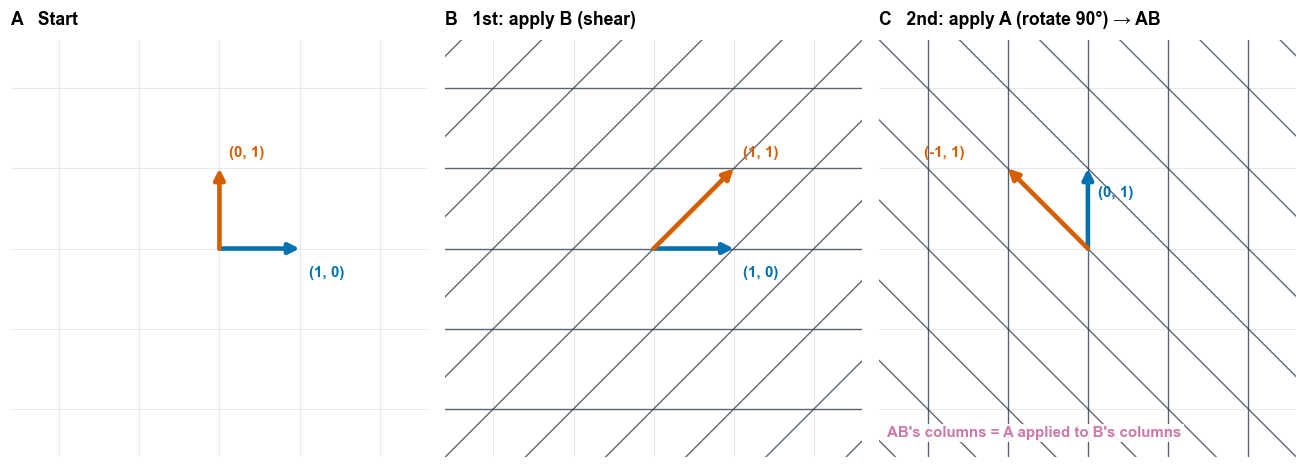

In [8]:
AB = draw_composition()

**그림에서 볼 것**
- A → B: 밀기 B 로 빨간 e2 가 (1, 1) 로 기웁니다. 파란 e1 은 (1, 0) 그대로입니다.
- B → C: 그 상태 전체를 90° 돌립니다. 파랑은 (0, 1) 로, 빨강은 (−1, 1) 로 갑니다.
- C 의 두 화살표가 곧 AB 의 두 열입니다. A 를 B 의 열에 각각 적용한 결과입니다.

이제 숫자로 유도의 4단계를 봅니다. A = [[1, 2], [3, 4]], B = [[5, 6], [7, 8]] 입니다.

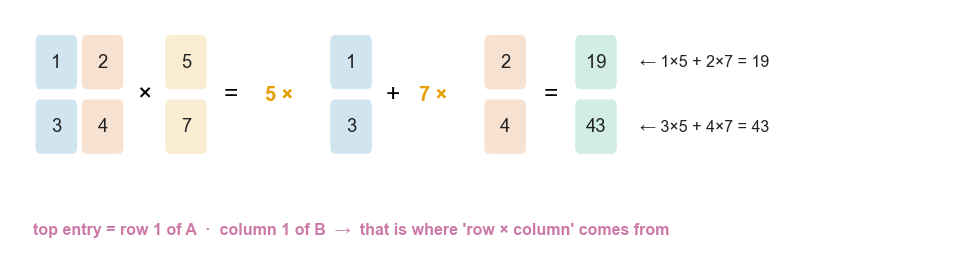

In [9]:
draw_row_col_origin()

**그림에서 볼 것**
- 왼쪽: AB 의 첫째 열을 만들려면 A 에 B 의 첫째 열(주황 5, 7) 을 곱합니다.
- 가운데: 2절대로 이것은 5 × (A 의 파란 1열) + 7 × (A 의 빨간 2열) 입니다.
- 오른쪽: 결과의 위 칸 19 = 1×5 + 2×7 은 A 의 **첫째 행** (1, 2) 와 B 의 **첫째 열** (5, 7) 의 내적입니다. 행 × 열은 여기서 나옵니다.

**수식 풀어 읽기**

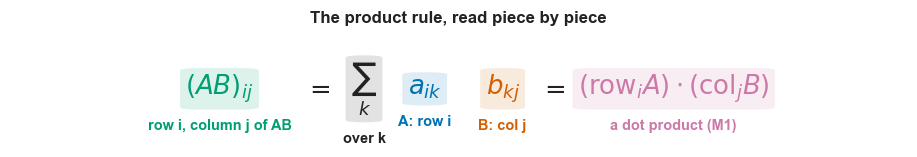

In [10]:
show_formula([(r"$(AB)_{ij}$", COL["result"], "row i, column j of AB"), (r"$=$", None, None),
              (r"$\sum_{k}$", COL["ink"], "over k"), (r"$a_{ik}$", COL["e1"], "A: row i"), (r"$\quad$", None, None),
              (r"$b_{kj}$", COL["e2"], "B: col j"), (r"$=$", None, None),
              (r"$(\mathrm{row}_i A)\cdot(\mathrm{col}_j B)$", COL["highlight"], "a dot product (M1)")],
             title="The product rule, read piece by piece")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $(AB)_{ij}$ | "AB 의 i 행 j 열 칸" | 결과 행렬의 한 칸 | 초록 칸 |
| $a_{ik}$ | "A 의 i 행 k 열" | A 의 i 번째 행을 따라 k 를 움직임 | A 의 행 |
| $b_{kj}$ | "B 의 k 행 j 열" | B 의 j 번째 열을 따라 k 를 움직임 | B 의 열 |
| $\sum_k$ | "k 를 바꿔 가며 모두 더한다" | 같은 k 끼리 짝지어 곱해 더함 = 내적 | 1×5 + 2×7 |

유도가 맞는지 두 가지로 확인합니다. (1) 숫자 예가 [[19, 22], [43, 50]] 인지, (2) 무작위 벡터를 "B 다음 A" 로 옮긴 것과 AB 한 번으로 옮긴 것이 늘 같은지.

In [11]:
A2 = np.array([[1, 2], [3, 4]]); B2 = np.array([[5, 6], [7, 8]])
assert np.array_equal(A2 @ B2, [[19, 22], [43, 50]])
rng = np.random.default_rng(0)
A_, B_ = rng.normal(size=(3, 3)), rng.normal(size=(3, 3)); X_ = rng.normal(size=(3, 1000))
assert np.allclose(A_ @ (B_ @ X_), (A_ @ B_) @ X_)                 # 이어 붙이기 = 곱 한 번
by_rule = np.array([[sum(A_[i, k] * B_[k, j] for k in range(3)) for j in range(3)] for i in range(3)])
assert np.allclose(by_rule, A_ @ B_)
print("AB =", (A2 @ B2).tolist(), "/ 무작위 1000개 벡터: B 다음 A == AB 한 번")

AB = [[19, 22], [43, 50]] / 무작위 1000개 벡터: B 다음 A == AB 한 번


> **역사 한 줄**: Gauss 는 『Disquisitiones arithmeticae』(1801) 에서 이차 형식의 계수 배열을 다루며 행렬 곱을 **합성(이어 붙이기)** 으로 생각해 설명했고, Eisenstein(1844) 은 선형 치환을 문자 하나로 쓰고 수처럼 곱하되 교환법칙이 성립하지 않음을 보였습니다. Cayley 의 1858년 논문 "A memoir on the theory of matrices" 가 행렬을 처음 추상적으로 정의하고 덧셈·곱셈·역행렬을 갖춘 행렬 대수를 내놓았습니다 [3][4].

## 4. 같은 곱을 보는 네 가지 눈

**한 줄 정의**: AB 는 (1) 내적의 표, (2) A 의 열을 섞은 열들, (3) B 의 행을 섞은 행들, (4) "A 의 k 열 × B 의 k 행" 조각들의 합입니다. 모두 같은 결과입니다.

**왜 필요한가**: 응용마다 편한 눈이 다릅니다. 어텐션 점수는 (1), signature 재구성은 (2), 신경망 배치는 (3), NMF·SVD(M5) 는 (4) 로 읽는 것이 자연스럽습니다.

**숫자로 따라가기**: 같은 A = [[1, 2], [3, 4]], B = [[5, 6], [7, 8]] 로 네 가지를 모두 봅니다. 결과는 [[19, 22], [43, 50]] 입니다.

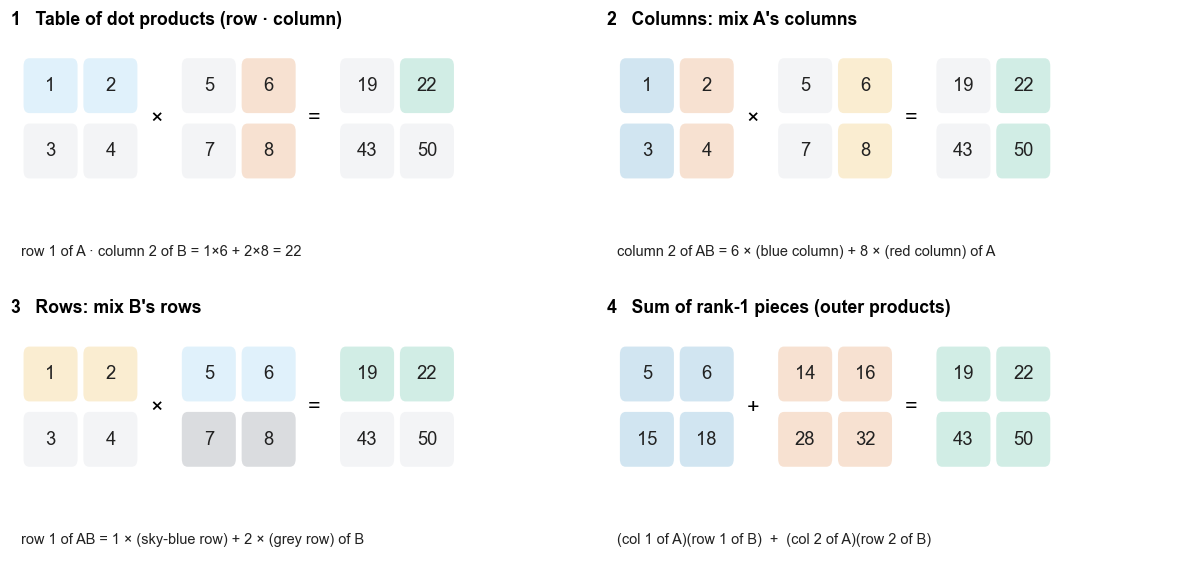

In [12]:
draw_four_views()

**그림에서 볼 것**
- 1: 하늘색으로 표시한 A 의 1행과 빨간 B 의 2열을 내적하면 초록 칸 22 입니다(행은 하늘색·회색, 열은 파랑·빨강으로 구분).
- 2: 주황으로 표시한 B 의 2열 (6, 8) 이 조리법입니다. A 의 파란 열을 6 번, 빨간 열을 8 번 더하면 AB 의 2열 (22, 50) 입니다.
- 3: 주황으로 표시한 A 의 1행 (1, 2) 가 조리법입니다. B 의 하늘색 행을 1 번, 회색 행을 2 번 더하면 AB 의 1행 (19, 22) 입니다.
- 4: (A 의 1열)(B 의 1행) 은 **모든 행이 한 행의 배수**인 표입니다. 이런 표를 rank-1 행렬이라 부릅니다(rank 는 M3 에서 정의). 이런 조각 두 개를 더하면 AB 입니다.

**수식 풀어 읽기** (네 번째 눈)

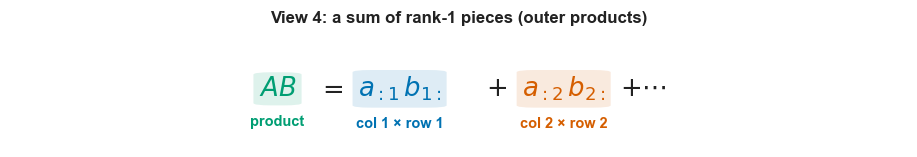

In [13]:
show_formula([(r"$AB$", COL["result"], "product"), (r"$=$", None, None),
              (r"$a_{:1}\,b_{1:}$", COL["e1"], "col 1 × row 1"), (r"$\quad+\quad$", None, None),
              (r"$a_{:2}\,b_{2:}$", COL["e2"], "col 2 × row 2"), (r"$+\cdots$", None, None)],
             title="View 4: a sum of rank-1 pieces (outer products)")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $a_{:k}$ | "A 의 k 번째 열" | 세로 벡터 | 4 의 파랑·빨강 |
| $b_{k:}$ | "B 의 k 번째 행" | 가로 벡터 | 4 의 파랑·빨강 |
| $a_{:k}\,b_{k:}$ | "열 곱하기 행(바깥곱)" | 표 한 장: 칸 (i, j) = $a_{ik} b_{kj}$ | 4 의 조각 한 장 |

네 가지 계산이 모두 `A @ B` 와 같은지 무작위 4 × 3, 3 × 5 행렬로 확인합니다.

In [14]:
P = rng.normal(size=(4, 3)); Q = rng.normal(size=(3, 5)); C = P @ Q
v1 = np.array([[P[i] @ Q[:, j] for j in range(5)] for i in range(4)])                # 내적의 표
v2 = np.column_stack([sum(Q[k, j] * P[:, k] for k in range(3)) for j in range(5)])   # 열 = A 열의 가중합
v3 = np.vstack([sum(P[i, k] * Q[k] for k in range(3)) for i in range(4)])            # 행 = B 행의 가중합
v4 = sum(np.outer(P[:, k], Q[k]) for k in range(3))                                   # rank-1 조각의 합
assert all(np.allclose(v, C) for v in (v1, v2, v3, v4))
assert all(np.linalg.matrix_rank(np.outer(P[:, k], Q[k])) == 1 for k in range(3))
print("네 가지 눈 모두 A @ B 와 같음. 조각 하나의 rank = 1")

네 가지 눈 모두 A @ B 와 같음. 조각 하나의 rank = 1


> **시퀀싱 데이터에서는** signature 행렬 P(96 × N) 와 노출량 행렬 E(N × 표본 수) 의 곱 P × E 를 네 번째 눈으로 읽으면, **signature 하나가 표본 전체에 남긴 몫(rank-1 조각)** 들을 겹쳐 쌓은 것이 catalogue 표 전체입니다 [5]. M5 의 NMF 는 이 조각들을 데이터에서 거꾸로 찾아냅니다.

## 5. 모양 규칙: 안쪽 크기가 맞아야 곱해진다

**한 줄 정의**: (m × n) 행렬과 (n × p) 행렬만 곱할 수 있고, 결과는 (m × p) 입니다. 가운데 n 이 맞아야 하고, 바깥 m, p 가 남습니다.

**왜 필요한가**: 행 × 열 내적은 짝지을 칸 수가 같아야 합니다. 앞 행렬의 행 길이(n)와 뒤 행렬의 열 길이(n)가 같아야 한다는 뜻입니다. 정사각이 아닌 행렬은 차원을 바꾸는 변환입니다(예: 3 × 2 행렬은 2 차원 벡터를 3 차원으로 보냄).

**숫자로 따라가기**: 표본 5개 × 유전자 3개 표에 유전자 가중치 3개를 곱하면 표본마다 점수 하나, 5 × 1 이 나옵니다.

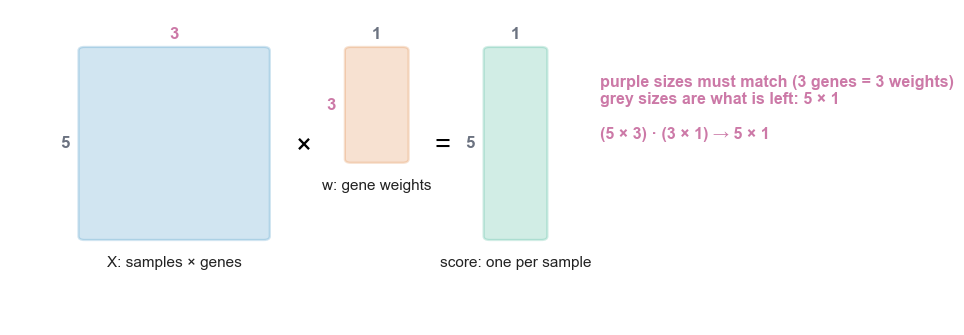

In [15]:
draw_shapes()

**그림에서 볼 것**
- 자주색 숫자(X 의 가로 3 = 유전자 수, w 의 세로 3 = 가중치 수)가 같아야 짝지어 곱할 수 있습니다.
- 회색 숫자(X 의 세로 5 = 표본 수, w 의 가로 1)가 결과 초록의 모양 5 × 1 이 됩니다.

In [16]:
X5 = rng.random((5, 3)); w3 = rng.random((3, 1))
assert (X5 @ w3).shape == (5, 1)
try:
    w3.T @ X5.T @ X5 @ np.ones((2, 1))       # 3 × 3 다음 2 × 1: 안쪽 크기가 안 맞음
    raise AssertionError("곱해지면 안 되는데 곱해졌습니다")
except ValueError as e:
    print("안쪽 크기가 다르면 numpy 가 거절합니다:", str(e)[:70])

안쪽 크기가 다르면 numpy 가 거절합니다: matmul: Input operand 1 has a mismatch in its core dimension 0, with g


## 6. 순서를 바꾸면 결과가 바뀐다: AB ≠ BA

**한 줄 정의**: 행렬 곱은 대개 순서를 바꿀 수 없습니다. "밀고 나서 돌리기"와 "돌리고 나서 밀기"는 다른 동작이기 때문입니다.

**왜 필요한가**: 숫자 곱셈에 익숙하면 AB 와 BA 를 같다고 착각하기 쉽습니다. 3절의 역사에서 Eisenstein 이 지적한 것도 이 성질입니다 [3].

**숫자로 따라가기**: R = 90° 회전 [[0, −1], [1, 0]], S = 밀기 [[1, 1], [0, 1]] 이면 RS = [[0, −1], [1, 1]], SR = [[1, −1], [1, 0]] 으로 다릅니다.

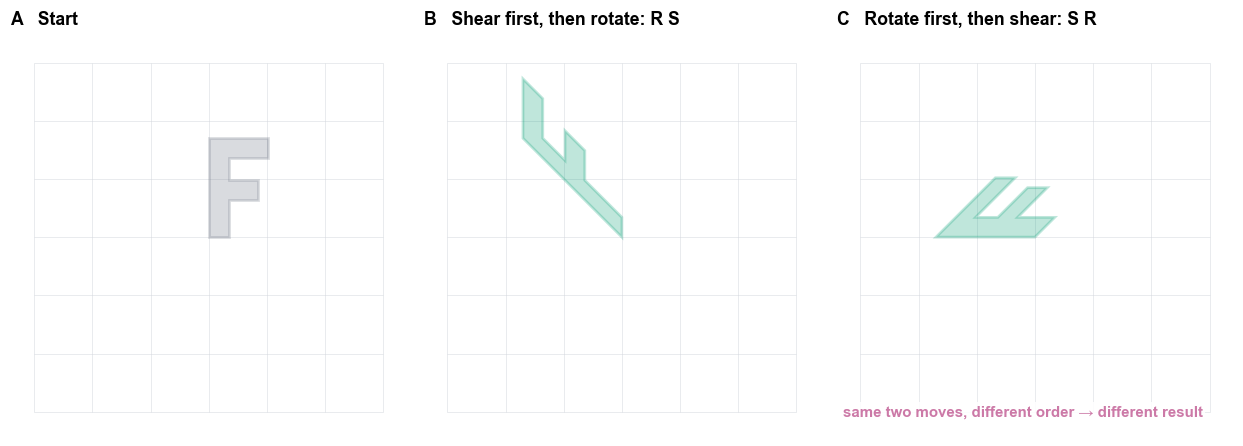

In [17]:
draw_order_matters()

**그림에서 볼 것**
- A 의 회색 F 를 두 순서로 옮겼습니다. B(밀기 먼저)와 C(회전 먼저)의 초록 F 가 서로 다른 자리, 다른 모양입니다.
- 행렬은 오른쪽부터 적용합니다. RS 는 "S 먼저, 그다음 R" 입니다.

In [18]:
R = np.array([[0, -1], [1, 0]]); S = np.array([[1, 1], [0, 1]])
assert np.array_equal(R @ S, [[0, -1], [1, 1]]) and np.array_equal(S @ R, [[1, -1], [1, 0]])
assert not np.array_equal(R @ S, S @ R)
print("RS =", (R @ S).tolist(), "  SR =", (S @ R).tolist())

RS = [[0, -1], [1, 1]]   SR = [[1, -1], [1, 0]]


## 7. 단위행렬, 역행렬, 행렬식: 되돌릴 수 있나

**한 줄 정의**
- 단위행렬 I 는 아무것도 옮기지 않는 변환입니다(열이 e1, e2 그대로).
- 역행렬 $A^{-1}$ 은 A 를 되돌리는 변환이라 $A^{-1}A = I$ 입니다.
- 행렬식(determinant) 은 A 가 넓이를 몇 배로 바꾸는지입니다(부호는 뒤집힘 여부). 2 × 2 에서는 $ad - bc$ 입니다.

**왜 필요한가**: 넓이가 0 이 되면(평면이 선으로 눌리면) 여러 점이 한 점으로 겹쳐 원래 자리를 알 수 없습니다. 그래서 **행렬식이 0 이면 역행렬이 없습니다**. M3 에서 "답이 하나로 정해지는가"와 같은 질문입니다.

**숫자로 따라가기**: [[2, 0.5], [0, 1]] 의 행렬식은 2×1 − 0.5×0 = 2 라 넓이가 2 배, [[1, 2], [0.5, 1]] 은 1×1 − 2×0.5 = 0 이라 선으로 눌립니다.

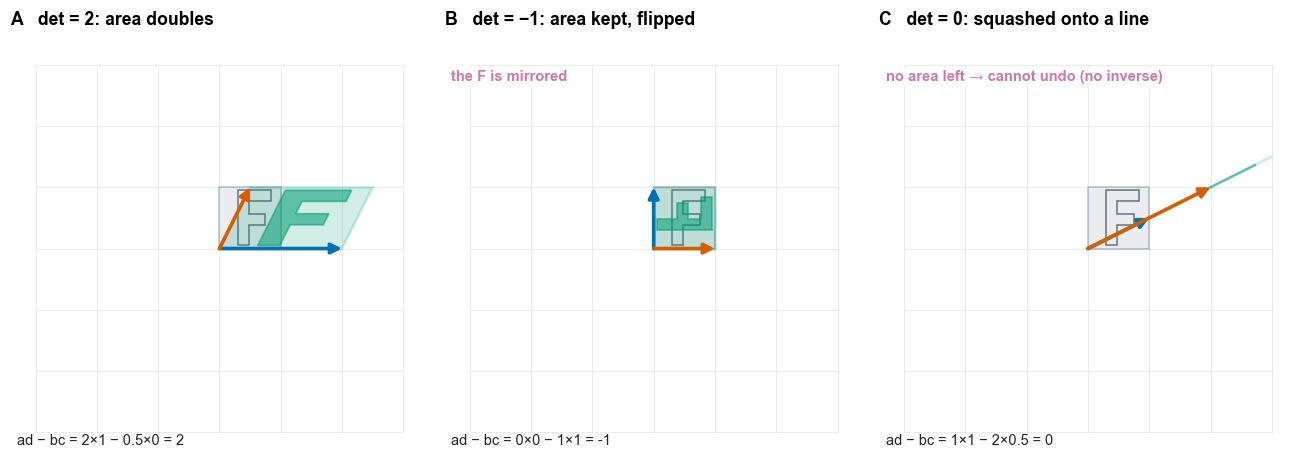

In [19]:
draw_determinant()

**그림에서 볼 것**
- 회색 정사각형(넓이 1)이 옅은 초록 평행사변형으로 바뀝니다. 그 넓이가 행렬식의 크기입니다. 안의 F(회색 선 → 진한 초록)는 모양이 어떻게 바뀌는지 보여 줍니다.
- B: 넓이는 1 그대로지만, 정사각형 안의 F 가 거울에 비친 모양(진한 초록)이 되고 파랑과 빨강의 순서가 뒤집혀 부호가 −1 입니다.
- C: 파랑과 빨강이 한 직선 위에 놓여 정사각형과 F 가 모두 선분으로 눌리고 넓이가 0 입니다. 이 변환은 되돌릴 수 없습니다.

**수식 풀어 읽기**

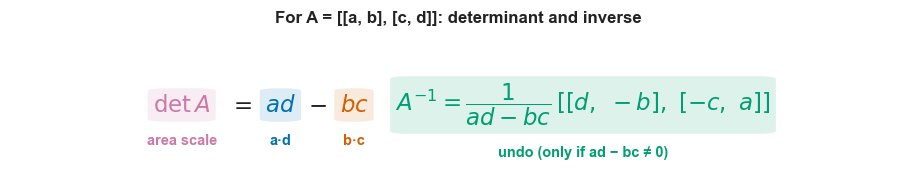

In [20]:
show_formula([(r"$\det A$", COL["highlight"], "area scale"), (r"$=$", None, None),
              (r"$ad$", COL["e1"], "a·d"), (r"$-$", None, None), (r"$bc$", COL["e2"], "b·c"), (r"$\qquad$", None, None),
              (r"$A^{-1} = \dfrac{1}{ad-bc}\,[[d,\ -b],\ [-c,\ a]]$", COL["result"], "undo (only if ad − bc ≠ 0)")],
             title="For A = [[a, b], [c, d]]: determinant and inverse", height=1.7, fontsize=15)

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\det A$ | "A 의 행렬식" | 넓이가 몇 배가 되나(부호는 뒤집힘) | 평행사변형 넓이 |
| $A^{-1}$ | "A 역행렬" | A 를 되돌리는 변환 | C 에는 없음 |
| $I$ | "단위행렬" | 아무것도 안 하는 변환 | 회색 정사각형 그대로 |

성질 세 가지를 확인합니다. (1) $A^{-1}A = I$, (2) 행렬식 0 이면 numpy 가 역행렬을 거절, (3) 넓이 배율은 이어 붙이면 곱해진다: $\det(AB) = \det A \det B$.

In [21]:
M1_ = np.array([[2.0, 0.5], [0.0, 1.0]]); M0 = np.array([[1.0, 2.0], [0.5, 1.0]])
assert np.allclose(np.linalg.inv(M1_) @ M1_, np.eye(2)) and np.isclose(np.linalg.det(M1_), 2)
assert np.isclose(np.linalg.det(M0), 0)
try:
    np.linalg.inv(M0); raise AssertionError("역행렬이 있으면 안 됩니다")
except np.linalg.LinAlgError:
    print("det = 0 인 행렬: 역행렬 없음 (numpy LinAlgError)")
A3, B3 = rng.normal(size=(4, 4)), rng.normal(size=(4, 4))
assert np.isclose(np.linalg.det(A3 @ B3), np.linalg.det(A3) * np.linalg.det(B3))
print("det(AB) = det(A) det(B):", round(np.linalg.det(A3 @ B3), 4))

det = 0 인 행렬: 역행렬 없음 (numpy LinAlgError)
det(AB) = det(A) det(B): 2.4587


곱의 역행렬은 순서가 뒤집힙니다: $(AB)^{-1} = B^{-1}A^{-1}$. "B 를 하고 A 를 했으면, 되돌릴 때는 A 부터 풀고 B 를 푼다"는 뜻으로, 양말을 신고 신발을 신었으면 벗을 때는 신발부터 벗는 것과 같습니다. 확인: $(AB)(B^{-1}A^{-1}) = A(BB^{-1})A^{-1} = AA^{-1} = I$.

In [22]:
assert np.allclose(np.linalg.inv(A3 @ B3), np.linalg.inv(B3) @ np.linalg.inv(A3))
assert not np.allclose(np.linalg.inv(A3 @ B3), np.linalg.inv(A3) @ np.linalg.inv(B3))
print("(AB)⁻¹ == B⁻¹A⁻¹, 그리고 A⁻¹B⁻¹ 와는 다름")

(AB)⁻¹ == B⁻¹A⁻¹, 그리고 A⁻¹B⁻¹ 와는 다름


## 8. 전치: 행과 열 바꾸기, 그리고 $(AB)^\top = B^\top A^\top$

**한 줄 정의**: 전치 $M^\top$ 는 대각선을 기준으로 뒤집어 행을 열로 바꾼 행렬입니다.

**왜 필요한가**: "표본 × 유전자" 를 "유전자 × 표본" 으로 돌려 봐야 할 때가 많고, 최소제곱(M3)의 $A^\top A$ 와 공분산(M4)의 $X^\top X$ 에 계속 나옵니다.

**숫자로 따라가기**: 2 × 3 행렬 [[1, 2, 3], [4, 5, 6]] 의 전치는 3 × 2 행렬 [[1, 4], [2, 5], [3, 6]] 입니다.

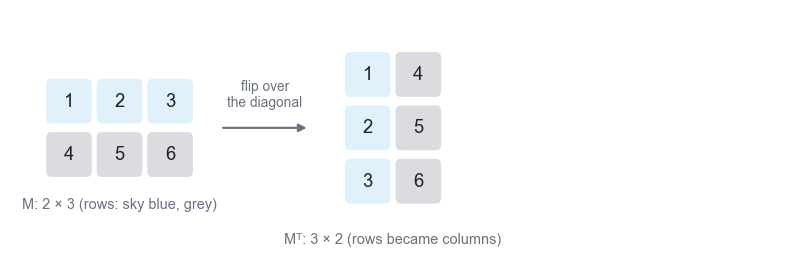

In [23]:
draw_transpose()

**그림에서 볼 것**
- 왼쪽의 하늘색 첫째 행 (1, 2, 3) 이 오른쪽에서는 하늘색 첫째 **열** 이 됩니다. 회색 행도 마찬가지입니다.

곱을 전치하면 순서가 뒤집힙니다: $(AB)^\top = B^\top A^\top$. 칸 하나로 증명합니다(이 노트북에서 유도).

$\big((AB)^\top\big)_{ij} = (AB)_{ji} = \sum_k a_{jk}\,b_{ki} = \sum_k (B^\top)_{ik}\,(A^\top)_{kj} = (B^\top A^\top)_{ij}$

모양으로도 보입니다. (m × n)(n × p) 를 뒤집으면 (p × n)(n × m) 순서여야 곱해집니다.

In [24]:
assert np.allclose((P @ Q).T, Q.T @ P.T)
print("(PQ)ᵀ == QᵀPᵀ:", np.allclose((P @ Q).T, Q.T @ P.T), "  모양:", (P @ Q).T.shape, "=", Q.T.shape, "@", P.T.shape)

(PQ)ᵀ == QᵀPᵀ: True   모양: (5, 4) = (5, 3) @ (3, 4)


## 9. 응용 1: 표본 × 유전자 표 × 가중치 = 표본마다 점수

**한 줄 정의**: 데이터 표 X(표본 × 유전자) 에 유전자 가중치 w 를 곱하면, 표본마다 "가중치를 준 합" 하나가 나옵니다.

**왜 필요한가**: 발현 점수, 회귀 예측값, 신경망의 한 층이 모두 이 모양입니다. 행 관점(3번째 눈)으로 보면 표본 하나(행)마다 내적 한 번입니다.

**숫자로 따라가기**: 아래 표본 1 의 점수는 0.5 × (유전자 1) + 0 × (유전자 2) + 1 × (유전자 3) − 0.5 × (유전자 4) 입니다.

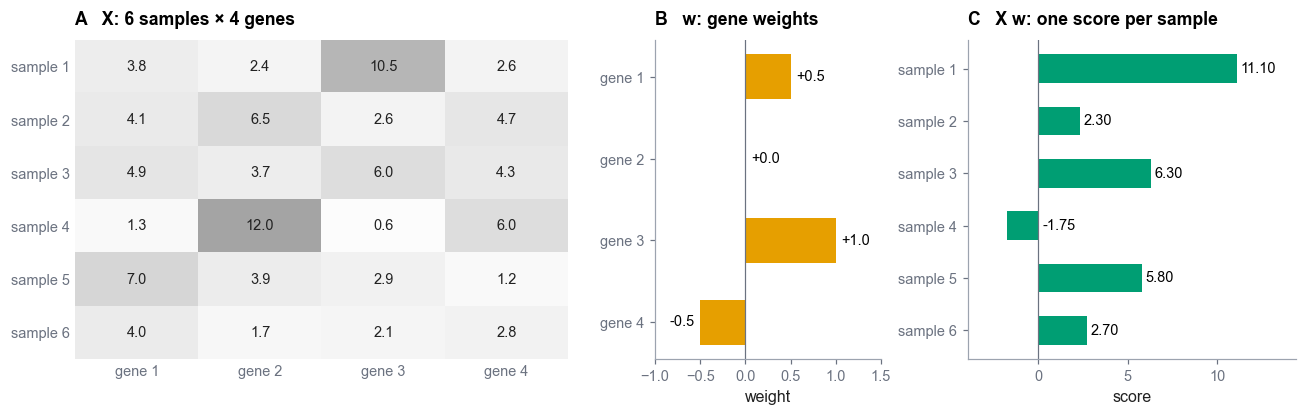

In [25]:
X6, w6, s6 = draw_samples_genes()

**그림에서 볼 것**
- A 의 한 행(표본 하나)과 B 의 가중치를 짝지어 곱해 더하면 C 의 막대 하나입니다.
- B 의 주황 막대가 가중치(조리법)입니다. 유전자 2 의 가중치가 0 이라 이 점수에는 유전자 2 가 전혀 들어가지 않고, 왼쪽으로 뻗은(음수) 유전자 4 는 점수를 깎습니다.

In [26]:
assert np.allclose(s6, [X6[i] @ w6 for i in range(6)])
print("표본 1 점수:", round(s6[0], 2), "=", " + ".join(f"{w6[j]:+.1f}×{X6[0, j]:.1f}" for j in range(4)))

표본 1 점수: 11.1 = +0.5×3.8 + +0.0×2.4 + +1.0×10.5 + -0.5×2.6


## 10. 응용 2: 신경망 한 층은 행렬 곱 + 더하기

**한 줄 정의**: 신경망의 한 층(선형 층)은 $y = Wx + b$ 이고, W 는 (출력 수 × 입력 수) 행렬입니다.

**왜 필요한가**: LLM 의 대부분 계산이 이 모양입니다. 입력 N 개를 한꺼번에 넣으면(배치) $Y = XW^\top + b$ 로, 행렬 곱 한 번이 됩니다. GPT-2 의 층을 직접 짠 것은 [CS329Z A2 노트북](../cs329z-llms-for-builders/lab02_attention.ipynb)에 있습니다.

**숫자로 따라가기**: 입력 3개, 출력 2개면 W 는 2 × 3 입니다. W 의 i 번째 행이 "출력 i 가 입력들을 얼마씩 섞는지"입니다.

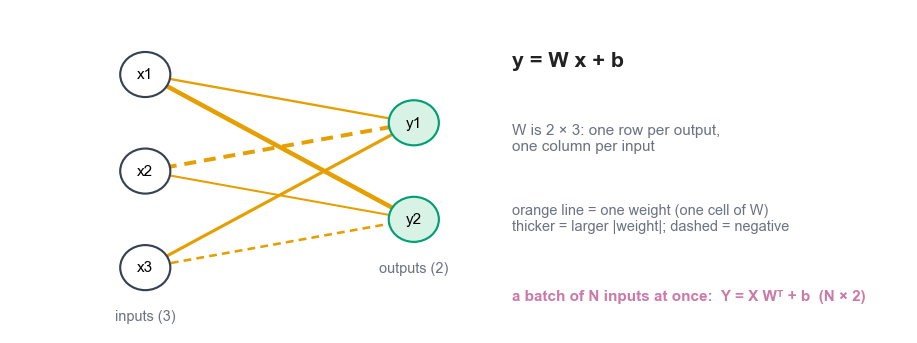

In [27]:
W = draw_nn_layer()

**그림에서 볼 것**
- 주황 선 하나가 W 의 칸 하나입니다. 굵을수록 가중치의 크기가 크고, 실선은 +, 점선은 − 입니다.
- 출력 y1 로 들어오는 세 선이 W 의 첫째 행입니다. 각 출력은 입력들의 가중합(내적)입니다.

In [28]:
xb = rng.normal(size=(8, 3)); bias = np.array([0.1, -0.2])
Y = xb @ W.T + bias
assert np.allclose(Y, np.array([W @ xi + bias for xi in xb]))
print("배치 8개를 한 번에:", Y.shape, "= 하나씩 8번 계산한 것과 같음")

배치 8개를 한 번에: (8, 2) = 하나씩 8번 계산한 것과 같음


## 11. 응용 3: 행렬 곱의 비용은 n³

**한 줄 정의**: n × n 행렬 두 개를 행 × 열 규칙으로 곱하면 결과 칸이 n² 개이고 칸마다 곱셈이 n 번이라, 곱셈은 모두 n³ 번입니다(이 노트북에서 셈).

**왜 필요한가**: 크기를 2 배로 하면 계산은 8 배가 됩니다. 큰 모델이 GPU 를 쓰고, 계산을 배치로 묶는 이유입니다. GPU 에서 계산과 메모리 중 무엇이 병목인지는 [CS329Z A5 노트북](../cs329z-llms-for-builders/lab05_inference.ipynb)에서 다룹니다.

**숫자로 따라가기**: n = 1024 이면 1024³ ≈ 10.7억 번입니다.

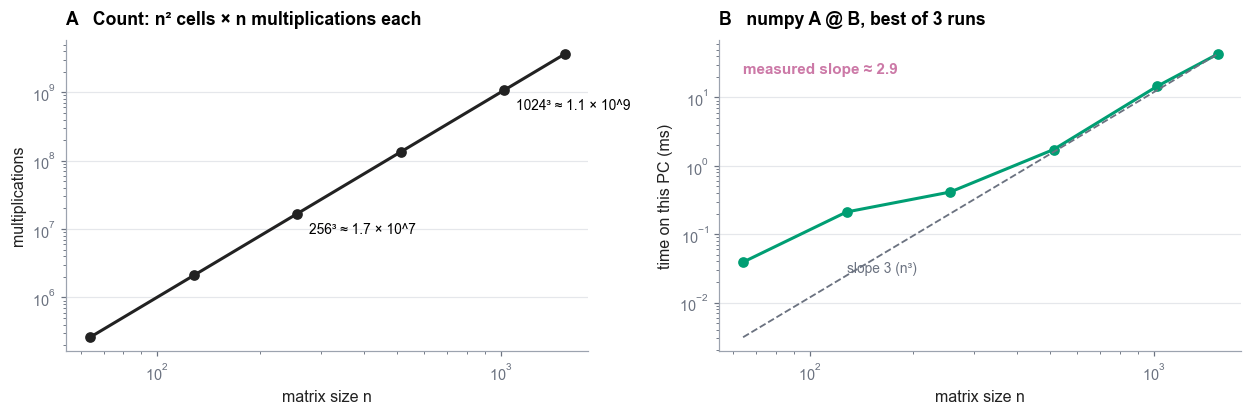

In [29]:
ns, times, slope = draw_cost()

**그림에서 볼 것**
- A: 곱셈 횟수는 로그 축에서 기울기 3 인 직선입니다.
- B: 이 PC 에서 잰 시간(초록)입니다. 작은 n 에서는 스레드 나누기와 캐시 때문에 들쭉날쭉해(구간에 따라 n³ 보다 가파르기도, 완만하기도 합니다) 기울기는 n ≥ 512 의 세 점으로만 쟀습니다. 측정값은 컴퓨터마다 다릅니다. numpy 는 최적화된 라이브러리를 써서 같은 n³ 계산을 아주 빠르게 합니다.

In [30]:
assert 1024 ** 3 == 1_073_741_824 and 1.5 < slope < 4.0
print(f"측정 기울기(n ≥ 512 의 세 점) = {slope:.2f}")

측정 기울기(n ≥ 512 의 세 점) = 2.94


## 연습 문제

1. A = [[1, 0], [0, 2]] 는 어떤 변환인가요? e1, e2 는 어디로 가나요?
2. [[2, 1], [1, 3]] × [[1, 0], [2, 1]] 을 행 × 열로 계산하세요.
3. 3 × 4 행렬과 4 × 2 행렬의 곱은 몇 × 몇인가요? 4 × 2 와 3 × 4 순서로는 곱할 수 있나요?
4. [[3, 6], [1, 2]] 의 역행렬이 있나요?

<details><summary>정답 보기</summary>

1. 세로(y) 방향으로만 2 배 늘이는 변환입니다. e1 은 (1, 0) 그대로, e2 는 (0, 2) 로 갑니다.
2. [[2×1 + 1×2, 2×0 + 1×1], [1×1 + 3×2, 1×0 + 3×1]] = [[4, 1], [7, 3]].
3. 3 × 2. 반대 순서는 안쪽 크기(2 와 3)가 달라 곱할 수 없습니다.
4. 없습니다. 행렬식이 3×2 − 6×1 = 0 입니다. 둘째 열이 첫째 열의 2 배라 평면이 선으로 눌립니다.

</details>

In [31]:
assert np.array_equal(np.array([[1, 0], [0, 2]]) @ np.array([0, 1]), [0, 2])
assert np.array_equal(np.array([[2, 1], [1, 3]]) @ np.array([[1, 0], [2, 1]]), [[4, 1], [7, 3]])
assert (np.ones((3, 4)) @ np.ones((4, 2))).shape == (3, 2)
assert np.isclose(np.linalg.det(np.array([[3, 6], [1, 2]])), 0)

## 정리

- 행렬은 공간을 옮기는 규칙이고, **열 = 기본 축이 가는 곳**입니다. 그래서 Ax 는 열의 가중합입니다.
- "B 다음 A" 를 행렬 하나로 쓰면 AB 의 열은 A × (B 의 열) 이 되고, 그 칸은 **A 의 행 · B 의 열** 입니다. 행 × 열은 이어 붙이기에서 나온 규칙입니다.
- 같은 곱을 내적의 표, 열의 가중합, 행의 가중합, rank-1 조각의 합으로 볼 수 있고, 응용마다 편한 눈이 다릅니다.
- 모양은 (m × n)(n × p) = m × p. 순서는 바꿀 수 없고, 행렬식이 0 이면 되돌릴 수 없으며, 전치하면 곱의 순서가 뒤집힙니다.
- signature × 노출량, 표본 × 유전자 × 가중치, 신경망 한 층이 모두 같은 행렬 곱입니다.

## 출처

1. MIT OpenCourseWare, 18.06 Linear Algebra (Gilbert Strang), Spring 2010, Video Lectures 목록. https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/video_galleries/video-lectures/ — 머리의 "같이 볼 강의" 회차와 제목.
2. 3Blue1Brown (Grant Sanderson), "Essence of linear algebra" 재생목록. https://www.youtube.com/playlist?list=PLZHQObOWTQDPD3MizzM2xVFitgF8hE_ab — 머리의 "같이 볼 강의" 장 번호와 제목만 확인했습니다(Chapter 3·4·6·7·8). 본문의 유도와 숫자는 이 노트북에서 직접 한 것이고, 이 출처에 기대지 않습니다.
3. O'Connor JJ, Robertson EF. "Matrices and determinants." MacTutor History of Mathematics, University of St Andrews (Last Update February 1996). https://mathshistory.st-andrews.ac.uk/HistTopics/Matrices_and_determinants/ — Gauss 가 『Disquisitiones arithmeticae』(1801)에서 행렬 곱을 "composition" 으로 생각해 설명했다는 문장, Eisenstein(1844) 이 선형 치환을 "add and multiply them like ordinary numbers except for the lack of commutativity" 한 문장, Cayley 1858 이 "the first abstract definition of a matrix" 이고 "a matrix algebra defining addition, multiplication, scalar multiplication and inverses" 를 내놓았다는 문장(3절 역사, 6절).
4. Cayley A. (1858). II. A memoir on the theory of matrices. *Philosophical Transactions of the Royal Society of London*, pp. 17–37. doi:10.1098/rstl.1858.0002 — Crossref 에서 서지 정보만 확인했고 원문은 열지 못했습니다(출판사 페이지 접근 거부). 내용은 [3] 을 따랐습니다.
5. Alexandrov LB, Nik-Zainal S, Wedge DC, Campbell PJ, Stratton MR (2013). Deciphering signatures of mutational processes operative in human cancer. *Cell Reports* 3(1):246–259. doi:10.1016/j.celrep.2012.12.008, PMID 23318258. — signature 행렬 P(K × N, K = 변이 종류 수) 와 노출량 E 에 대해 catalogue 를 "M ≈ P × E" (Equation 3) 로 쓴 모형(2·4절 시퀀싱 상자).